# Greenhouse detection & segmentation: YOLO ➜ SAM 3

Pipeline:
1. **YOLO (Ultralytics)** predicts greenhouse bounding boxes.
2. **SAM 3** takes each predicted box as a prompt and returns a greenhouse mask.
3. **Metrics**: detection metrics for YOLO, segmentation metrics for SAM 3 (instance + pixel level).
4. **Plots**: ground truth vs predicted boxes and masks.

**Ground truth used**
- **GT boxes** come from the YOLO label files (`cls xc yc w h`, or polygons).
- **GT masks** come from the binary mask images in `GT_MASKS_DIR` (same file name as the image), or from polygon labels if your labels have them.
  Without GT masks, SAM 3 cannot be scored at pixel level, so the notebook falls back to comparing the box around each SAM mask with the GT boxes.

**What was fixed in this version**
- GT masks are now loaded from the mask images (box-only labels gave SAM 3 *zero* GT objects, so all of its scores were 0).
- Pixel metrics are reported as *N/A* (not 0) when no GT mask exists.
- Nested duplicate YOLO boxes (a big box covering boxes that were already detected) are removed.
- New **grouping-agnostic** scores (area IoU of the union of boxes/masks), which stay fair when the GT labels a whole greenhouse complex as one box while YOLO detects each tunnel.
- A **data check** cell that reports label format, mask coverage and suspicious GT labels.

In [1]:
# %pip install -q -U "ultralytics>=8.3.237" opencv-python matplotlib pandas

## 1. Configuration

In [2]:
from pathlib import Path

# ---- paths ----
IMAGES_DIR   = Path(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_yolo_dataset\images\val")
LABELS_DIR   = Path(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_yolo_dataset\labels\val")
# binary GT masks (white = greenhouse), same file name stem as the image. Set to None if you have none.
GT_MASKS_DIR = Path(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks")
YOLO_WEIGHTS = r"C:\Users\alias\Documents\yolo26n\weights\best.pt"
SAM_WEIGHTS  = "sam3.pt"                   # fallback: "sam2.1_b.pt"
OUT_DIR      = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# ---- settings ----
GREENHOUSE_CLASS_IDS = None   # e.g. [0]; None = every class is greenhouse
N_EVAL      = 200             # number of images to evaluate (None = all; 21k images takes a long time)
YOLO_CONF   = 0.25            # confidence threshold for YOLO boxes
YOLO_IOU    = 0.5             # NMS IoU
CONTAIN_THR = 0.8             # drop a box if >=80% of a higher-scoring box lies inside it (or vice versa); None = off
IMG_SIZE    = 640
MATCH_IOU   = 0.5             # IoU threshold for a true positive
DEVICE      = 0               # GPU index, or "cpu"
N_PLOTS     = 6               # how many images to visualize

## 2. Imports & helpers

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ultralytics import YOLO, SAM

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = sorted(p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
if N_EVAL:
    image_paths = image_paths[:N_EVAL]
print(f"Evaluating {len(image_paths)} images")

mask_index = {}
if GT_MASKS_DIR is not None and Path(GT_MASKS_DIR).exists():
    mask_index = {p.stem: p for p in Path(GT_MASKS_DIR).iterdir() if p.suffix.lower() in IMG_EXTS}
print(f"GT mask files found: {len(mask_index)}  |  matched to evaluated images: "
      f"{sum(p.stem in mask_index for p in image_paths)}")


def load_gt(label_path, h, w):
    """Read a YOLO label file -> list of dicts {box: [x1,y1,x2,y2] px, mask: HxW bool or None, kind}."""
    objs = []
    if not label_path.exists():
        return objs
    for line in label_path.read_text().strip().splitlines():
        vals = line.split()
        if len(vals) < 5:
            continue
        cls = int(float(vals[0]))
        if GREENHOUSE_CLASS_IDS is not None and cls not in GREENHOUSE_CLASS_IDS:
            continue
        coords = np.array(vals[1:], dtype=float)
        if len(coords) == 4:                       # bbox: xc yc bw bh
            xc, yc, bw, bh = coords * [w, h, w, h]
            box = [xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2]
            objs.append({"box": box, "mask": None, "kind": "box"})
        else:                                      # polygon
            poly = coords.reshape(-1, 2) * [w, h]
            mask = np.zeros((h, w), np.uint8)
            cv2.fillPoly(mask, [poly.round().astype(np.int32)], 1)
            box = [poly[:, 0].min(), poly[:, 1].min(), poly[:, 0].max(), poly[:, 1].max()]
            objs.append({"box": box, "mask": mask.astype(bool), "kind": "polygon"})
    return objs


def load_gt_mask(stem, h, w):
    """Binary GT mask (HxW bool) from GT_MASKS_DIR, resized to the image, or None."""
    p = mask_index.get(stem)
    if p is None:
        return None
    m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    if m is None:
        return None
    if m.shape != (h, w):
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
    return m > (127 if m.max() > 1 else 0)


def boxes_to_mask(boxes, h, w):
    """Union of boxes as a filled HxW bool mask."""
    m = np.zeros((h, w), bool)
    for x1, y1, x2, y2 in np.asarray(boxes).reshape(-1, 4):
        x1, y1 = max(int(np.floor(x1)), 0), max(int(np.floor(y1)), 0)
        x2, y2 = min(int(np.ceil(x2)), w), min(int(np.ceil(y2)), h)
        m[y1:y2, x1:x2] = True
    return m


def mask_to_box(m):
    ys, xs = np.where(m)
    if len(xs) == 0:
        return [0, 0, 0, 0]
    return [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]


def remove_contained(boxes, scores, thr):
    """Drop the lower-scoring box of any pair where >= thr of the smaller box lies inside the other."""
    if thr is None or len(boxes) < 2:
        return np.arange(len(boxes))
    order = np.argsort(-scores); keep = []
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    for i in order:
        ok = True
        for j in keep:
            ix = max(0, min(boxes[i, 2], boxes[j, 2]) - max(boxes[i, 0], boxes[j, 0]))
            iy = max(0, min(boxes[i, 3], boxes[j, 3]) - max(boxes[i, 1], boxes[j, 1]))
            if ix * iy / max(min(area[i], area[j]), 1e-9) >= thr:
                ok = False; break
        if ok:
            keep.append(i)
    return np.array(sorted(keep), dtype=int)


def box_iou(a, b):
    """IoU matrix between boxes a (N,4) and b (M,4), xyxy."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def mask_iou(a, b):
    """IoU matrix between mask lists a (N,H,W) and b (M,H,W)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    A = np.stack(a).reshape(len(a), -1).astype(np.float32)
    B = np.stack(b).reshape(len(b), -1).astype(np.float32)
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return inter / (union + 1e-9)


def greedy_match(iou, scores, thr):
    """Match predictions (rows, highest score first) to GT (cols). Returns tp flags and matched IoUs."""
    order = np.argsort(-np.asarray(scores))
    used = set(); tp = np.zeros(iou.shape[0], bool); matched = np.zeros(iou.shape[0])
    for i in order:
        if iou.shape[1] == 0:
            break
        cand = [(iou[i, j], j) for j in range(iou.shape[1]) if j not in used and iou[i, j] >= thr]
        if cand:
            v, j = max(cand)
            used.add(j); tp[i] = True; matched[i] = v
    return tp, matched


def average_precision(records, n_gt):
    """All-point interpolated AP. records = list of (score, is_tp)."""
    if n_gt == 0 or not records:
        return 0.0
    rec = sorted(records, key=lambda r: -r[0])
    tps = np.cumsum([r[1] for r in rec]); fps = np.cumsum([not r[1] for r in rec])
    recall = tps / n_gt; precision = tps / np.maximum(tps + fps, 1e-9)
    mrec = np.concatenate([[0], recall, [1]]); mpre = np.concatenate([[1], precision, [0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

Evaluating 200 images
GT mask files found: 105931  |  matched to evaluated images: 200


## 3. Load models

In [4]:
yolo = YOLO(YOLO_WEIGHTS)
sam  = SAM(SAM_WEIGHTS)   # SAM 3 with box (visual) prompts: one mask per box
print("YOLO classes:", yolo.names)

YOLO classes: {0: 'greenhouse'}


## 4. Run the pipeline: YOLO boxes ➜ SAM 3 masks
YOLO predicts boxes → nested duplicates are removed → the boxes are passed to SAM 3 as prompts, so mask *i* belongs to box *i* and inherits its confidence.

GT instance masks: polygon labels if present; otherwise the GT mask image cropped to each GT box.

In [5]:
from tqdm.auto import tqdm

results = []   # one dict per image
for img_path in tqdm(image_paths[:5]):
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    gt = load_gt(LABELS_DIR / f"{img_path.stem}.txt", h, w)

    # ---- GT semantic mask (all greenhouse pixels) ----
    gt_sem = load_gt_mask(img_path.stem, h, w)
    if gt_sem is None and any(o["mask"] is not None for o in gt):
        gt_sem = np.any([o["mask"] for o in gt if o["mask"] is not None], axis=0)
    # GT instance masks for box-only labels: semantic mask clipped to each GT box
    if gt_sem is not None:
        for o in gt:
            if o["mask"] is None:
                o["mask"] = gt_sem & boxes_to_mask([o["box"]], h, w)

    # ---- 1) YOLO detection ----
    det = yolo.predict(img, conf=YOLO_CONF, iou=YOLO_IOU, imgsz=IMG_SIZE, device=DEVICE, verbose=False)[0]
    boxes  = det.boxes.xyxy.cpu().numpy()
    scores = det.boxes.conf.cpu().numpy()
    clss   = det.boxes.cls.cpu().numpy().astype(int)
    if GREENHOUSE_CLASS_IDS is not None:
        keep = np.isin(clss, GREENHOUSE_CLASS_IDS)
        boxes, scores = boxes[keep], scores[keep]
    keep = remove_contained(boxes, scores, CONTAIN_THR)
    boxes, scores = boxes[keep], scores[keep]

    # ---- 2) SAM 3 segmentation prompted by YOLO boxes ----
    pred_masks = []
    if len(boxes):
        seg = sam.predict(img, bboxes=boxes.tolist(), device=DEVICE, verbose=False)[0]
        if seg.masks is not None:
            m = seg.masks.data.cpu().numpy()
            if m.shape[1:] != (h, w):
                m = np.stack([cv2.resize(x.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST) for x in m])
            pred_masks = [x.astype(bool) for x in m]
        n = min(len(pred_masks), len(boxes))   # keep boxes and masks aligned
        boxes, scores, pred_masks = boxes[:n], scores[:n], pred_masks[:n]

    results.append({
        "path": img_path, "h": h, "w": w,
        "gt_boxes": np.array([o["box"] for o in gt]).reshape(-1, 4),
        "gt_masks": [o["mask"] for o in gt],
        "gt_kinds": [o["kind"] for o in gt],
        "gt_sem": gt_sem,
        "pred_boxes": boxes, "pred_scores": scores, "pred_masks": pred_masks,
    })

print("Total GT objects:", sum(len(r["gt_boxes"]) for r in results))
print("Total predictions:", sum(len(r["pred_boxes"]) for r in results))

  0%|          | 0/5 [00:00<?, ?it/s]

WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
Total GT objects: 27
Total predictions: 15


### Data check
Run this before trusting any number. It reports the label format, how many images have a GT mask, and flags images where the GT boxes look wrong. A GT box is flagged when less than 30 % of it is greenhouse in the GT mask; this usually means the label file belongs to another image or was converted wrongly.

In [6]:
n_box  = sum(k == "box" for r in results for k in r["gt_kinds"])
n_poly = sum(k == "polygon" for r in results for k in r["gt_kinds"])
n_mask = sum(r["gt_sem"] is not None for r in results)
HAS_GT_MASKS = n_mask > 0
print(f"GT label lines: {n_box} boxes, {n_poly} polygons")
print(f"Images with a GT mask: {n_mask}/{len(results)}")
if not HAS_GT_MASKS:
    print("⚠ No GT masks: SAM 3 is evaluated by the box around each mask, and pixel metrics are N/A.\n"
          "  Point GT_MASKS_DIR to your mask images (same names as the images) for real segmentation scores.")

suspicious = []
for r in results:
    if r["gt_sem"] is None:
        continue
    for b in r["gt_boxes"]:
        bm = boxes_to_mask([b], r["h"], r["w"])
        fill = (r["gt_sem"] & bm).sum() / max(bm.sum(), 1)
        if fill < 0.3:
            suspicious.append((r["path"].name, round(float(fill), 3)))
print(f"GT boxes with <30% greenhouse pixels inside: {len(suspicious)}")
pd.DataFrame(suspicious, columns=["image", "greenhouse fraction in GT box"]).groupby("image").size().rename("bad GT boxes").sort_values(ascending=False).head(15)

GT label lines: 27 boxes, 0 polygons
Images with a GT mask: 5/5
GT boxes with <30% greenhouse pixels inside: 27


image
103.png    20
102.png     4
10.png      1
109.png     1
11.png      1
Name: bad GT boxes, dtype: int64

## 5. Metrics
**Instance level** (one-to-one matching at IoU ≥ `MATCH_IOU`): Precision, Recall, F1, AP50, AP50-95, mean IoU of matches.
- *YOLO (boxes)*: predicted boxes vs GT boxes.
- *SAM 3 (masks)*: predicted masks vs GT instance masks. If there are no GT masks, the box around each SAM mask is compared with the GT boxes instead.

**Area level (grouping-agnostic)**: all predicted pixels vs all GT pixels per image, summed over the dataset. This does not care whether a greenhouse complex is labelled as one object or ten, so it is the fairest score when the labelling granularity is inconsistent.
- *YOLO*: union of predicted boxes vs union of GT boxes.
- *SAM 3*: union of predicted masks vs the GT mask.

In [7]:
IOU_THRS = np.arange(0.5, 0.96, 0.05)

def instance_metrics(kind):
    """kind = 'box', 'mask' or 'maskbox' (box around each SAM mask vs GT boxes)."""
    recs = {t: [] for t in IOU_THRS}; n_gt = 0; tp50 = fp50 = 0; matched_ious = []
    for r in results:
        if kind == "box":
            gt_items, pr_items = r["gt_boxes"], r["pred_boxes"]
            iou = box_iou(pr_items, gt_items)
        elif kind == "maskbox":
            gt_items = r["gt_boxes"]
            pr_items = np.array([mask_to_box(m) for m in r["pred_masks"]]).reshape(-1, 4)
            iou = box_iou(pr_items, gt_items)
        else:
            if r["gt_sem"] is None:          # no mask GT for this image -> skip it entirely
                continue
            gt_items, pr_items = r["gt_masks"], r["pred_masks"]
            iou = mask_iou(pr_items, gt_items)
        sc = r["pred_scores"][:len(pr_items)]
        n_gt += len(gt_items)
        for t in IOU_THRS:
            tp, m = greedy_match(iou, sc, t)
            recs[t] += list(zip(sc, tp))
            if np.isclose(t, MATCH_IOU):
                tp50 += tp.sum(); fp50 += (~tp).sum(); matched_ious += list(m[tp])
    P = tp50 / max(tp50 + fp50, 1); R = tp50 / max(n_gt, 1)
    aps = [average_precision(recs[t], n_gt) for t in IOU_THRS]
    return {
        "GT objects": n_gt, "Predictions": int(tp50 + fp50), "TP": int(tp50), "FP": int(fp50), "FN": int(n_gt - tp50),
        "Precision": P, "Recall": R, "F1": 2 * P * R / max(P + R, 1e-9),
        "AP50": aps[0], "AP50-95": float(np.mean(aps)),
        "Mean IoU (matched)": float(np.mean(matched_ious)) if matched_ious else 0.0,
    }

def area_metrics(kind):
    """Pixel-level scores of the union of predictions vs the union of GT. kind = 'box' or 'mask'."""
    TP = FP = FN = TN = 0; n = 0
    for r in results:
        h, w = r["h"], r["w"]
        if kind == "box":
            gt, pr = boxes_to_mask(r["gt_boxes"], h, w), boxes_to_mask(r["pred_boxes"], h, w)
        else:
            if r["gt_sem"] is None:
                continue
            gt = r["gt_sem"]; pr = np.zeros((h, w), bool)
            for m in r["pred_masks"]: pr |= m
        n += 1
        TP += (gt & pr).sum(); FP += (~gt & pr).sum(); FN += (gt & ~pr).sum(); TN += (~gt & ~pr).sum()
    if n == 0:
        return {k: np.nan for k in ["Images", "IoU", "Dice / F1", "Precision", "Recall", "Accuracy"]}
    return {
        "Images": n, "IoU": TP / max(TP + FP + FN, 1), "Dice / F1": 2 * TP / max(2 * TP + FP + FN, 1),
        "Precision": TP / max(TP + FP, 1), "Recall": TP / max(TP + FN, 1),
        "Accuracy": (TP + TN) / max(TP + FP + FN + TN, 1),
    }

det_metrics = instance_metrics("box")
if HAS_GT_MASKS:
    seg_metrics, seg_name = instance_metrics("mask"), "SAM 3 (masks)"
else:
    seg_metrics, seg_name = instance_metrics("maskbox"), "SAM 3 (box around mask)"

summary = pd.DataFrame({"YOLO (boxes)": det_metrics, seg_name: seg_metrics})
area = pd.DataFrame({"YOLO (box area)": area_metrics("box"), "SAM 3 (mask vs GT mask)": area_metrics("mask")})

print(f"Instance-level metrics @ IoU {MATCH_IOU}")
display(summary.style.format("{:.4f}", na_rep="N/A"))
print("Area-level metrics (grouping-agnostic)")
display(area.style.format("{:.4f}", na_rep="N/A"))

summary.to_csv(OUT_DIR / "instance_metrics.csv")
area.to_csv(OUT_DIR / "area_metrics.csv")

Instance-level metrics @ IoU 0.5


,YOLO (boxes),SAM 3 (masks)
GT objects,27.0000,27.0000
Predictions,15.0000,15.0000
TP,5.0000,0.0000
FP,10.0000,15.0000
FN,22.0000,27.0000
Precision,0.3333,0.0000
Recall,0.1852,0.0000
F1,0.2381,0.0000
AP50,0.1083,0.0000
AP50-95,0.0841,0.0000


Area-level metrics (grouping-agnostic)


,YOLO (box area),SAM 3 (mask vs GT mask)
Images,5.0000,5.0000
IoU,0.5219,0.0000
Dice / F1,0.6859,0.0000
Precision,0.7992,0.0000
Recall,0.6007,0.0000
Accuracy,0.8299,0.8765


### Per-image metrics

In [8]:
rows = []
for r in results:
    h, w = r["h"], r["w"]
    tp_b, _ = greedy_match(box_iou(r["pred_boxes"], r["gt_boxes"]), r["pred_scores"], MATCH_IOU)
    gtb, prb = boxes_to_mask(r["gt_boxes"], h, w), boxes_to_mask(r["pred_boxes"], h, w)
    ub = (gtb | prb).sum()
    row = {"image": r["path"].name, "GT": len(r["gt_boxes"]), "Pred": len(r["pred_boxes"]),
           "Box TP": int(tp_b.sum()), "Box-area IoU": (gtb & prb).sum() / ub if ub else np.nan,
           "Mask TP": np.nan, "Mask IoU": np.nan}
    if r["gt_sem"] is not None:
        tp_m, _ = greedy_match(mask_iou(r["pred_masks"], r["gt_masks"]),
                               r["pred_scores"][:len(r["pred_masks"])], MATCH_IOU)
        pr = np.zeros((h, w), bool)
        for m in r["pred_masks"]: pr |= m
        u = (r["gt_sem"] | pr).sum()
        row["Mask TP"] = int(tp_m.sum())
        row["Mask IoU"] = (r["gt_sem"] & pr).sum() / u if u else np.nan
    rows.append(row)

per_image = pd.DataFrame(rows)
SORT_COL = "Mask IoU" if per_image["Mask IoU"].notna().any() else "Box-area IoU"
per_image = per_image.sort_values(SORT_COL, na_position="first")
per_image.to_csv(OUT_DIR / "per_image_metrics.csv", index=False)
per_image.head(20)

,image,GT,Pred,Box TP,Box-area IoU,Mask TP,Mask IoU
0,10.png,1,0,0,0.000000,0,NaN
1,102.png,4,4,4,0.895718,0,0.0
2,103.png,20,1,0,0.576008,0,0.0
3,109.png,1,4,1,0.406028,0,0.0
4,11.png,1,6,0,0.777598,0,0.0


### Metrics chart

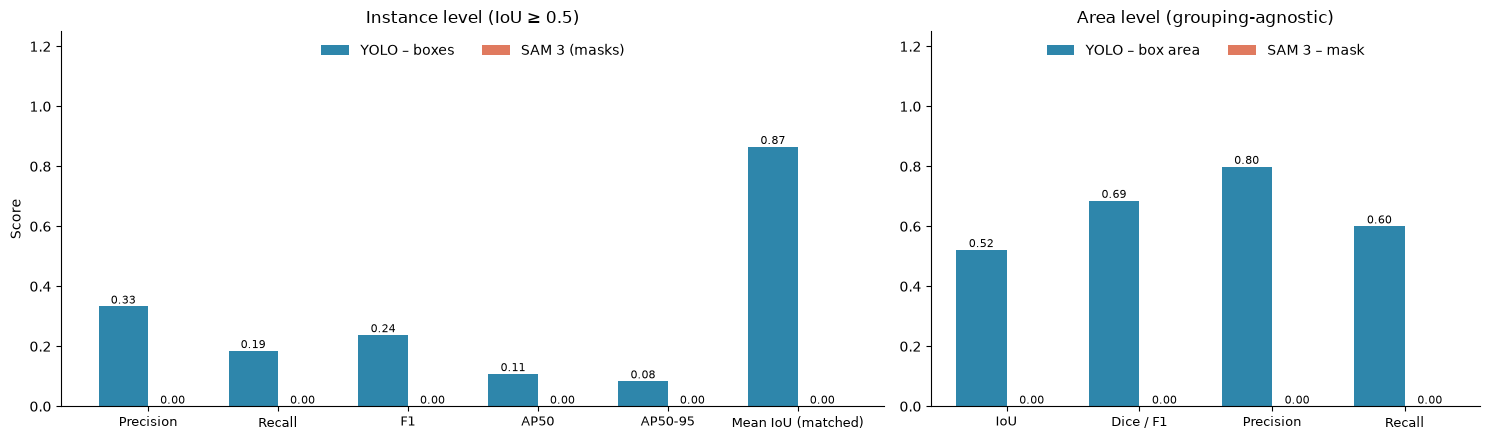

In [9]:
keys = ["Precision", "Recall", "F1", "AP50", "AP50-95", "Mean IoU (matched)"]
x = np.arange(len(keys)); bw = 0.38
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
b1 = ax.bar(x - bw/2, [det_metrics[k] for k in keys], bw, label="YOLO – boxes", color="#2E86AB")
b2 = ax.bar(x + bw/2, [seg_metrics[k] for k in keys], bw, label=seg_name, color="#E07A5F")
ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x, keys, fontsize=9); ax.set_ylim(0, 1.25); ax.set_ylabel("Score")
ax.set_title(f"Instance level (IoU ≥ {MATCH_IOU})"); ax.legend(frameon=False, loc="upper center", ncol=2)

ax = axes[1]; akeys = ["IoU", "Dice / F1", "Precision", "Recall"]; xa = np.arange(len(akeys))
va = [area.loc[k, "YOLO (box area)"] for k in akeys]
vb = [area.loc[k, "SAM 3 (mask vs GT mask)"] for k in akeys]
c1 = ax.bar(xa - bw/2, va, bw, label="YOLO – box area", color="#2E86AB")
c2 = ax.bar(xa + bw/2, np.nan_to_num(vb), bw, label="SAM 3 – mask", color="#E07A5F")
ax.bar_label(c1, fmt="%.2f", fontsize=8)
ax.bar_label(c2, labels=["N/A" if np.isnan(v) else f"{v:.2f}" for v in vb], fontsize=8)
ax.set_xticks(xa, akeys, fontsize=9); ax.set_ylim(0, 1.25)
ax.set_title("Area level (grouping-agnostic)"); ax.legend(frameon=False, loc="upper center", ncol=2)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "metrics_bar.png", dpi=150); plt.show()

## 6. Visualize: ground truth vs prediction
Left: image + **GT** (green mask & boxes). Middle: image + **prediction** (red YOLO boxes with confidence, SAM 3 masks). Right: error map — green = TP pixels, red = FP pixels, blue = FN pixels (against the GT mask, or against the GT boxes if there is no mask).

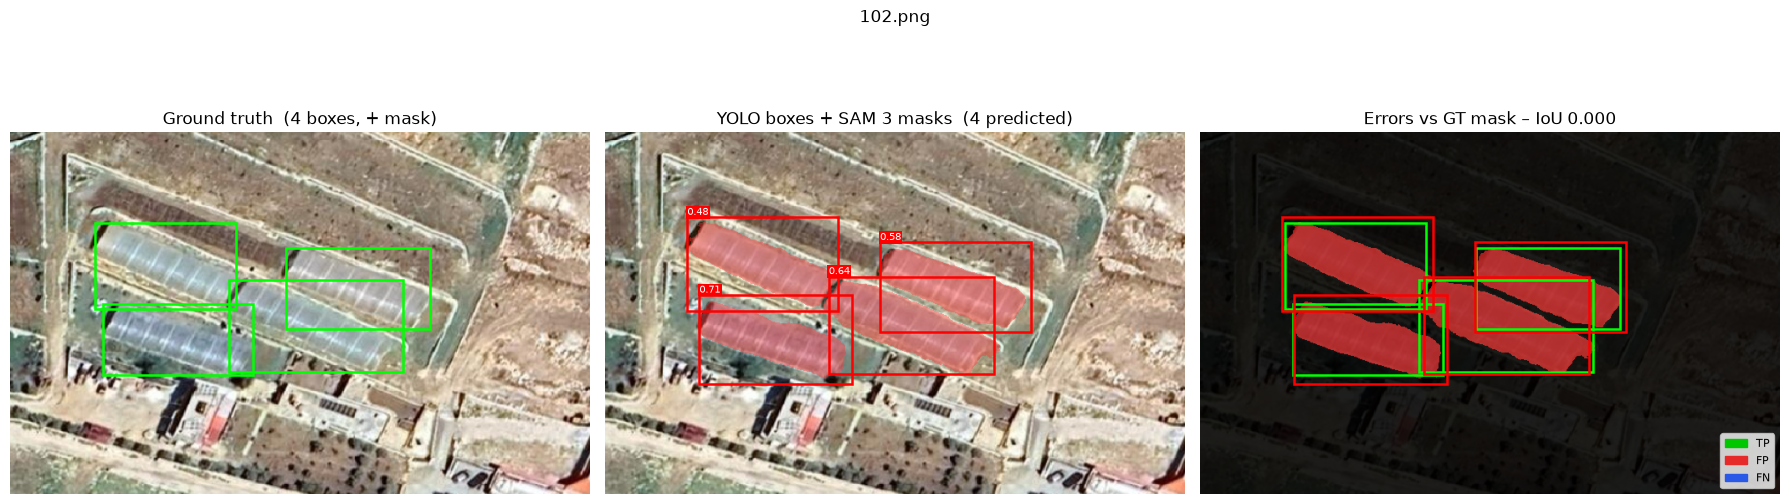

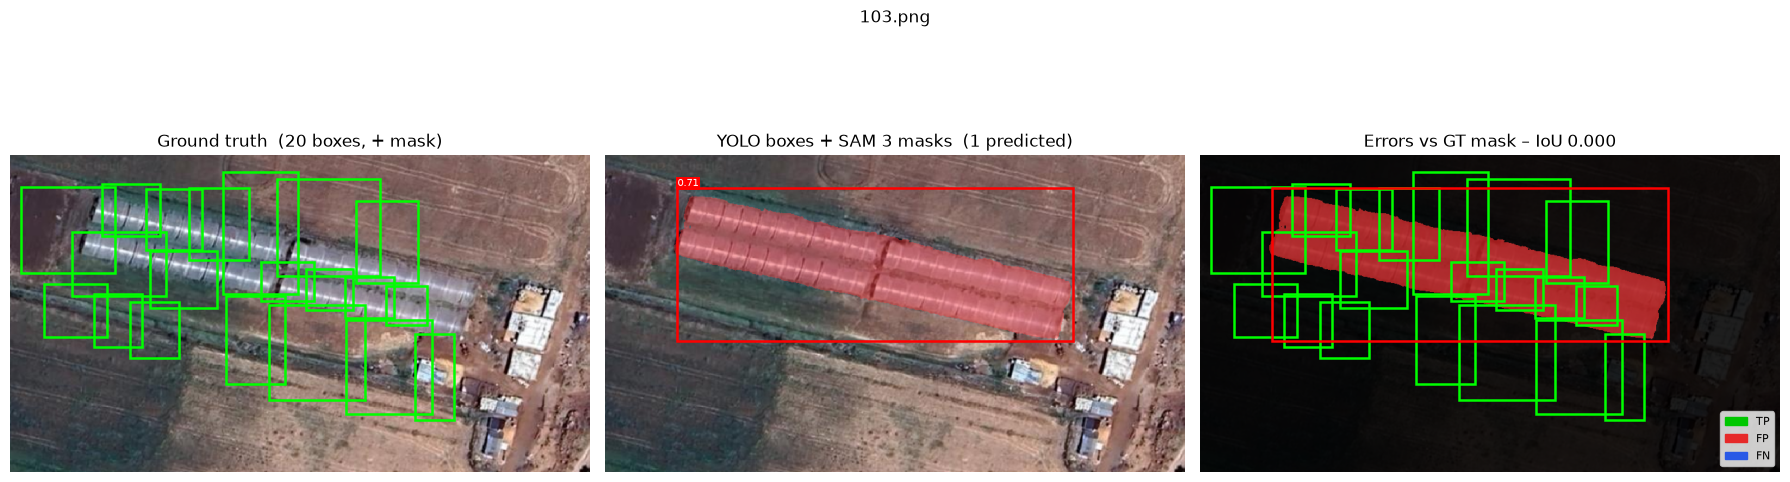

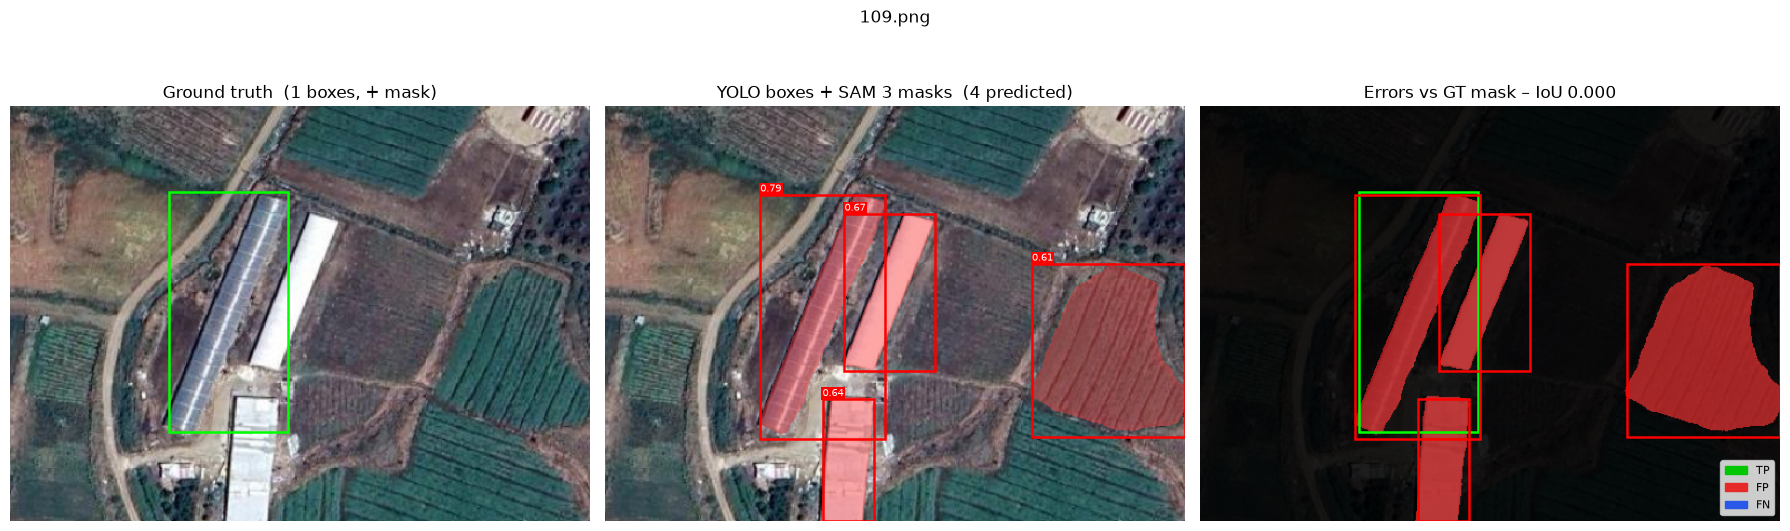

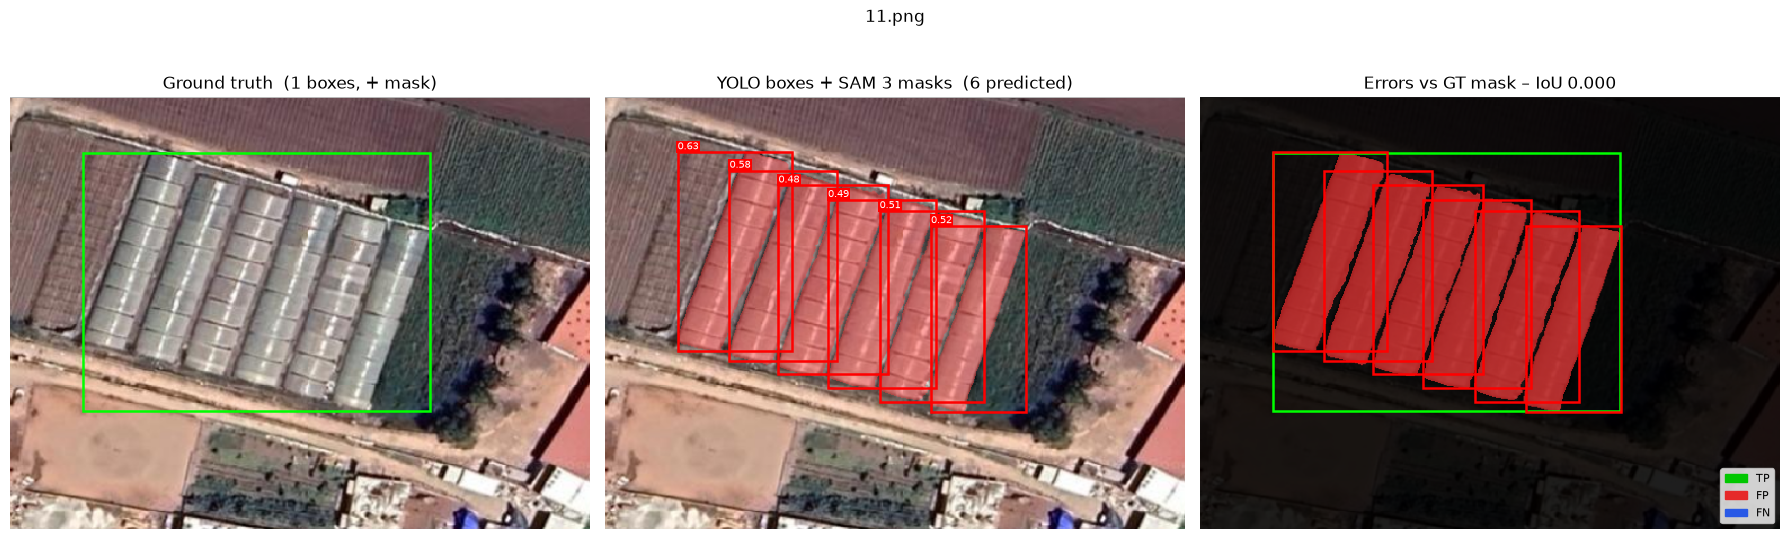

In [10]:
def overlay(img_rgb, masks, color, alpha=0.45):
    out = img_rgb.astype(np.float32).copy()
    for m in masks:
        if m is None: continue
        out[m] = out[m] * (1 - alpha) + np.array(color) * alpha
    return out.astype(np.uint8)

def draw_boxes(ax, boxes, color, scores=None):
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.8))
        if scores is not None:
            ax.text(x1, y1 - 3, f"{scores[i]:.2f}", color="white", fontsize=7,
                    bbox=dict(fc=color, ec="none", pad=1))

def plot_result(r):
    img = cv2.cvtColor(cv2.imread(str(r["path"])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    has_mask = r["gt_sem"] is not None
    gt_u = r["gt_sem"] if has_mask else boxes_to_mask(r["gt_boxes"], h, w)
    pr_u = np.zeros((h, w), bool)
    for m in r["pred_masks"]: pr_u |= m
    err = np.zeros((h, w, 3), np.uint8)
    err[gt_u & pr_u] = (0, 200, 0); err[~gt_u & pr_u] = (230, 40, 40); err[gt_u & ~pr_u] = (40, 90, 230)
    union = (gt_u | pr_u).sum(); piou = (gt_u & pr_u).sum() / union if union else float("nan")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(overlay(img, [r["gt_sem"]] if has_mask else [], (0, 255, 0)))
    draw_boxes(axes[0], r["gt_boxes"], "lime")
    axes[0].set_title(f"Ground truth  ({len(r['gt_boxes'])} boxes{', + mask' if has_mask else ', no mask'})")
    axes[1].imshow(overlay(img, r["pred_masks"], (255, 60, 60)))
    draw_boxes(axes[1], r["pred_boxes"], "red", r["pred_scores"])
    axes[1].set_title(f"YOLO boxes + SAM 3 masks  ({len(r['pred_boxes'])} predicted)")
    axes[2].imshow((img * 0.4).astype(np.uint8)); axes[2].imshow(err, alpha=0.7)
    draw_boxes(axes[2], r["gt_boxes"], "lime"); draw_boxes(axes[2], r["pred_boxes"], "red")
    axes[2].set_title(f"Errors vs GT {'mask' if has_mask else 'boxes'} – IoU {piou:.3f}")
    axes[2].legend(handles=[mpatches.Patch(color=(0, .78, 0), label="TP"),
                            mpatches.Patch(color=(.9, .16, .16), label="FP"),
                            mpatches.Patch(color=(.16, .35, .9), label="FN")], loc="lower right", fontsize=8)
    for a in axes: a.axis("off")
    fig.suptitle(r["path"].name, fontsize=12)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"viz_{r['path'].stem}.png", dpi=130); plt.show()

# worst and best images
ranked = per_image.dropna(subset=[SORT_COL])["image"].tolist() or per_image["image"].tolist()
by_name = {r["path"].name: r for r in results}
picks = ranked[: N_PLOTS // 2] + ranked[-(N_PLOTS - N_PLOTS // 2):]
for name in dict.fromkeys(picks):
    plot_result(by_name[name])

## Notes
- **Labelling granularity.** Some GT labels box a whole greenhouse complex, while YOLO detects each tunnel (e.g. `10.png`, `11.png`). Instance metrics count those as errors even when the prediction is visually right; the area-level scores do not. Report both, and fix or relabel these images if you need fair instance metrics.
- **Suspicious GT boxes.** Check the images listed in the data check (e.g. `103.png`). They usually mean a label file was converted wrongly or belongs to another image.
- `CONTAIN_THR` removes nested duplicate YOLO boxes; set it to `None` to see YOLO's raw output.
- SAM masks inherit YOLO confidences, so a greenhouse missed by YOLO is also missed by SAM 3.
- All metrics, per-image tables and figures are saved to `outputs/`.